# Chapitre 6 - Cours 1 : Architecture RAG et algorithmes de recherche

Un modèle a besoin de deux choses pour résoudre une tâche : des **instructions** (communes à
toutes les requêtes, sujet du chapitre 5) et des **informations** propres à chaque requête.
Ce chapitre traite de la **construction du contexte**, avec deux grands schémas : le **RAG**
(*retrieval-augmented generation*, on va chercher l'information dans une mémoire externe) et
les **agents** (le modèle utilise des outils pour agir et s'informer).

Ce premier notebook couvre les sections *RAG*, *RAG Architecture* et *Retrieval Algorithms*
(jusqu'à *Comparing retrieval algorithms*) :

1. pourquoi construire un contexte : RAG contre « long contexte », en tokens et en dollars ;
2. l'architecture d'un système RAG (indexation, recherche, génération) et notre corpus jouet ;
3. la recherche par termes : fréquence des termes, IDF, index inversé, TF-IDF ;
4. BM25, implémenté à la main et comparé à `rank_bm25` ;
5. la recherche par embeddings (MiniLM anglais et multilingue) ;
6. la recherche vectorielle exacte et approchée (idées d'IVF et de HNSW, mesures avec FAISS) ;
7. la comparaison des deux familles (qualité, vitesse, coût).

In [1]:
import os

os.environ["HF_HUB_OFFLINE"] = "1"          # modèles déjà en cache : aucun appel réseau
os.environ["HF_HUB_VERBOSITY"] = "error"
import logging
import time
import warnings

import faiss
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from rank_bm25 import BM25Okapi
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from transformers import AutoTokenizer

from aie import llm
from aie import ch06_rag_agents as c6
from aie.diagrams import Diagram
from aie.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                          annotate_bars, finish, set_style, subtitle)

set_style()
warnings.filterwarnings("ignore")
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)
llm.seed_everything(0)
pd.set_option("display.max_colwidth", 90)
P = c6.passages()
TEXTS, IDS = [p.text for p in P], [p.pid for p in P]
qwen_tok = AutoTokenizer.from_pretrained(llm.SMALL)  # tokenizer seul : pas de GPU nécessaire ici

## 1. Pourquoi construire un contexte ? (section *RAG*)

Le RAG consiste à **récupérer** (*retrieve*) les informations pertinentes dans une mémoire
externe (base de documents interne, historique de conversations, Web) puis à les donner au
modèle pour qu'il **génère** sa réponse. L'idée remonte au schéma « chercher puis lire » de
Chen et al. (2017) ; le terme RAG vient de Lewis et al. (2020).

**Intuition.** Un modèle sans contexte est comme un étudiant à un examen à livre fermé : il
répond de mémoire, et invente quand il ne sait pas. Le RAG lui donne, pour chaque question,
les quelques pages utiles du manuel. Le livre compare la construction du contexte à
l'**ingénierie des variables** (*feature engineering*) du ML classique : dans les deux cas, on
fournit au modèle l'information nécessaire pour traiter l'entrée.

Un long contexte rend-il le RAG inutile ? L'auteure pense que non, pour deux raisons :
(i) les données disponibles croissent plus vite que les fenêtres de contexte ; (ii) un modèle
qui *accepte* un long contexte ne l'*utilise* pas forcément bien, et chaque token coûte.
Chiffrons la seconde raison. Pour une base de $B$ tokens, une requête « tout dans le
contexte » consomme $B$ tokens d'entrée, alors qu'un RAG qui renvoie $k$ morceaux de $c$
tokens consomme environ $k\,c + q$ tokens (question comprise), **indépendamment de $B$**.
Côté calcul, le coût de l'attention du pré-remplissage croît même en $O(B^2)$.

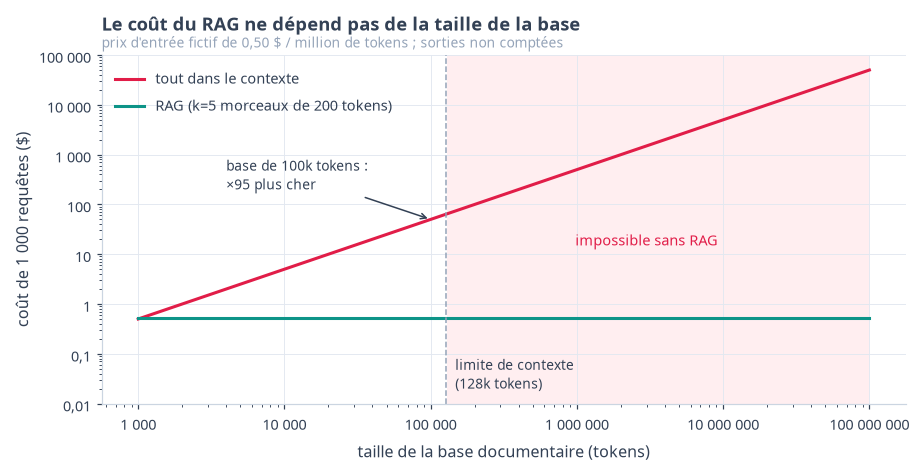

In [2]:
B = np.logspace(3, 8, 200)                       # taille de la base documentaire (tokens)
prix = 0.50 / 1e6                                 # prix fictif : 0,50 $ par million de tokens d'entrée
k, c, q = 5, 200, 50
cout_long = B * prix * 1000                       # coût pour 1 000 requêtes
cout_rag = np.full_like(B, (k * c + q) * prix * 1000)
limite = 128_000

fig, ax = plt.subplots(figsize=(8.5, 4.4))
ax.loglog(B, cout_long, color=ROSE, label="tout dans le contexte")
ax.loglog(B, cout_rag, color=TEAL, label=f"RAG (k={k} morceaux de {c} tokens)")
ax.axvline(limite, color=GRAY, ls="--", lw=1)
ax.text(limite * 1.15, 2e-2, "limite de contexte\n(128k tokens)", fontsize=9, color=SLATE)
ax.fill_between(B[B > limite], 1e-3, 1e6, color=LIGHT[ROSE], alpha=0.6, lw=0)
ax.text(3e6, 1.5e1, "impossible sans RAG", color=ROSE, fontsize=9.5, ha="center")
ax.set_xlabel("taille de la base documentaire (tokens)")
ax.set_ylabel("coût de 1 000 requêtes ($)")
ax.set_ylim(1e-2, 1e5)
fmt = plt.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", " ") if v >= 1 else f"{v:g}".replace(".", ","))
ax.yaxis.set_major_formatter(fmt); ax.xaxis.set_major_formatter(fmt)
ax.set_title("Le coût du RAG ne dépend pas de la taille de la base", pad=16)
subtitle(ax, "prix d'entrée fictif de 0,50 $ / million de tokens ; sorties non comptées")
ax.legend(loc="upper left")
ratio = 100_000 / (k * c + q)
ax.annotate(f"base de 100k tokens :\n×{ratio:.0f} plus cher", xy=(1e5, 1e5 * prix * 1000), xytext=(4e3, 2e2),
            arrowprops=dict(arrowstyle="->", color=SLATE), fontsize=9)
finish(fig)
plt.show()

Même quand la base tient dans la fenêtre (Anthropic suggérait en 2024 de tout mettre dans le
prompt sous ~200 000 tokens pour Claude), chaque requête paie toute la base : pour 100 000
tokens, un facteur d'environ 100 par rapport à un RAG à 5 morceaux. Le *prompt caching*
(chapitre 9) atténue ce coût, mais pas la dilution de l'attention.

> **À retenir.** Le RAG construit un contexte **spécifique à chaque requête**. Son coût par
> requête est constant ($\approx k\,c$ tokens) alors que celui du « tout dans le contexte »
> croît avec la base ; au-delà de la fenêtre du modèle, il n'y a pas d'alternative.

## 2. Architecture d'un système RAG (section *RAG Architecture*)

Un système RAG a deux composants : un **retriever** (récupérateur) qui va chercher
l'information, et un **générateur** qui rédige la réponse. Le retriever a lui-même deux
fonctions : l'**indexation** (préparer les données hors ligne pour qu'on les retrouve vite) et
l'**interrogation** (*querying*). Les documents longs sont d'abord **découpés** en morceaux
(*chunks*) ; comme le livre, on appellera « document » aussi bien un document qu'un morceau.
Dans l'article original, retriever et générateur étaient entraînés ensemble ; aujourd'hui,
on assemble le plus souvent des composants pré-entraînés séparément.

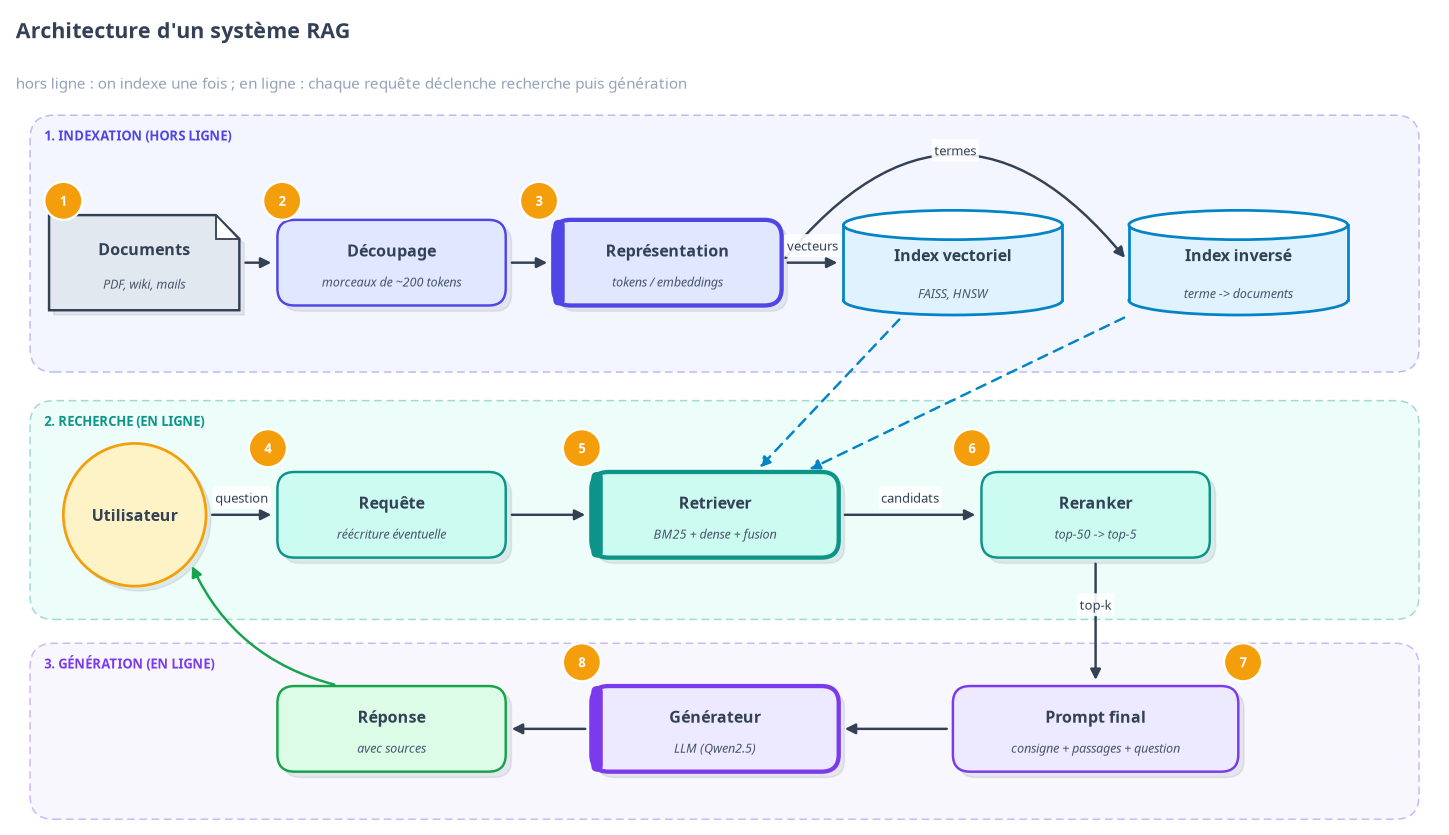

In [3]:
d = Diagram(15, 7.6, title="Architecture d'un système RAG",
            subtitle="hors ligne : on indexe une fois ; en ligne : chaque requête déclenche recherche puis génération")
d.group(0.2, 4.75, 14.8, 7.45, "1. Indexation (hors ligne)", color=INDIGO)
d.group(0.2, 2.15, 14.8, 4.45, "2. Recherche (en ligne)", color=TEAL)
d.group(0.2, 0.05, 14.8, 1.9, "3. Génération (en ligne)", color=VIOLET)
d.box("docs", 1.4, 5.9, "Documents", sub="PDF, wiki, mails", color=SLATE, kind="doc", w=2.0, h=1.0)
d.box("chunk", 4.0, 5.9, "Découpage", sub="morceaux de ~200 tokens", color=INDIGO, w=2.4)
d.box("enc", 6.9, 5.9, "Représentation", sub="tokens / embeddings", color=INDIGO, w=2.4, kind="model")
d.box("vec", 9.9, 5.9, "Index vectoriel", sub="FAISS, HNSW", color=SKY, kind="db", w=2.3, h=1.1)
d.box("inv", 12.9, 5.9, "Index inversé", sub="terme -> documents", color=SKY, kind="db", w=2.3, h=1.1)
d.arrow("docs", "chunk"); d.arrow("chunk", "enc"); d.arrow("enc", "vec", "vecteurs")
d.arrow("enc", "inv", "termes", rad=-0.62, label_offset=(0, 0.05))
d.box("user", 1.3, 3.25, "Utilisateur", color=AMBER, kind="user", w=1.5)
d.box("rew", 4.0, 3.25, "Requête", sub="réécriture éventuelle", color=TEAL, w=2.4)
d.box("ret", 7.4, 3.25, "Retriever", sub="BM25 + dense + fusion", color=TEAL, w=2.6, kind="model")
d.box("rr", 11.4, 3.25, "Reranker", sub="top-50 -> top-5", color=TEAL, w=2.4)
d.arrow("user", "rew", "question"); d.arrow("rew", "ret"); d.arrow("ret", "rr", "candidats")
d.arrow("vec", "ret", style="dashed", color=SKY); d.arrow("inv", "ret", style="dashed", color=SKY)
d.box("prompt", 11.4, 1.0, "Prompt final", sub="consigne + passages + question", color=VIOLET, w=3.0)
d.box("gen", 7.4, 1.0, "Générateur", sub="LLM (Qwen2.5)", color=VIOLET, kind="model", w=2.6)
d.box("ans", 4.0, 1.0, "Réponse", sub="avec sources", color=GREEN, w=2.4)
d.arrow("rr", "prompt", "top-k"); d.arrow("prompt", "gen"); d.arrow("gen", "ans")
d.arrow("ans", "user", color=GREEN, rad=-0.25)
for (x, y, t) in [(0.55, 6.55, "1"), (2.85, 6.55, "2"), (5.55, 6.55, "3"), (2.7, 3.95, "4"), (6.0, 3.95, "5"),
                  (10.1, 3.95, "6"), (12.95, 1.7, "7"), (6.0, 1.7, "8")]:
    d.badge(x, y, t)
d.show()

**Notre corpus.** Pour expérimenter, le module `aie.ch06_rag_agents` contient un petit corpus
français rédigé à la main : 10 documents (manuel d'un thermostat fictif « Thermo-X200 »,
guide RH d'une entreprise fictive « Calypso », boutique fictive de mode pour chats « Minou
Chic », erreurs réseau Linux, cuisine vietnamienne, système solaire, jardinage...), soit 64
passages, et **42 questions annotées** avec leurs passages pertinents. Deux documents parlent
de « transformateurs » (électriques et réseaux de neurones) et un troisième du film
*Transformers* : de quoi piéger la recherche lexicale. Les faits « fictifs » (prix, codes
d'erreur, règles RH) ne peuvent pas être connus du modèle : sans RAG, il ne peut qu'inventer.

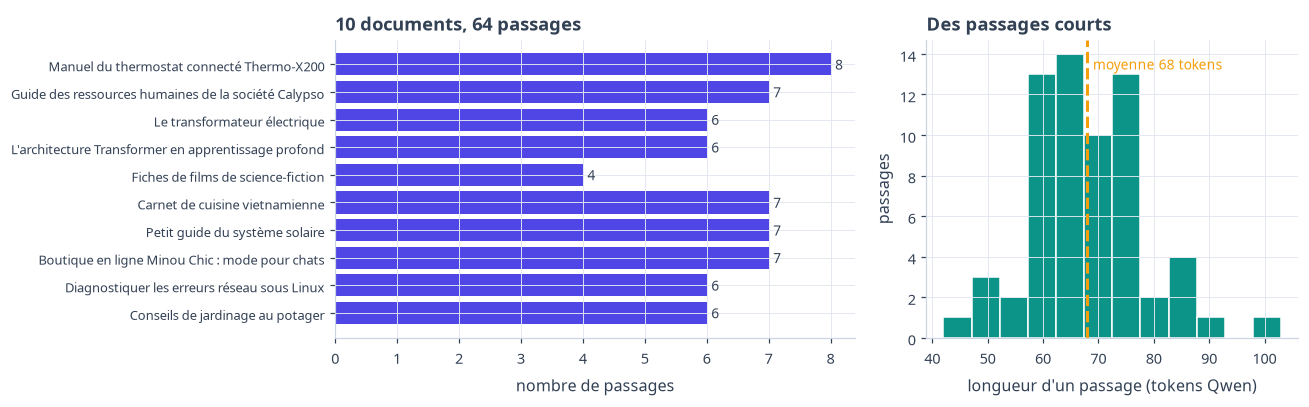

Types de questions : {'semantique': 20, 'lexical': 19, 'ambigu': 3}


,qid,question,relevant,type
0,q01,Que signifie le code E-42 sur le Thermo-X200 ?,{'thermo-4': 1},lexical
1,q08,Combien de jours de vacances ai-je par an chez Calypso ?,{'rh-1': 1},semantique
2,q15,Comment fonctionne un transformateur électrique ?,"{'transfo-1': 2, 'transfo-2': 1}",ambigu
3,q22,Quelles épices parfument le bouillon du phở ?,{'cuisine-1': 1},lexical
4,q29,Combien de temps la lumière solaire met-elle à nous parvenir ?,{'solaire-7': 1},semantique
5,q36,Que signifie l'erreur EADDRNOTAVAIL ?,{'reseau-2': 1},lexical


In [4]:
lens = np.array([len(qwen_tok(t)["input_ids"]) for t in TEXTS])
par_doc = pd.DataFrame({"document": [d_["title"] for d_ in c6.DOCUMENTS],
                        "passages": [len(d_["paragraphs"]) for d_ in c6.DOCUMENTS]})
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.4, 1]})
ax = axes[0]
ax.barh(par_doc.document[::-1], par_doc.passages[::-1], color=INDIGO)
annotate_bars(ax, "{:.0f}")
ax.set_xlabel("nombre de passages"); ax.set_title("10 documents, 64 passages")
ax.tick_params(axis="y", labelsize=8.5)
ax = axes[1]
ax.hist(lens, bins=12, color=TEAL, edgecolor="white")
ax.axvline(lens.mean(), color=AMBER, ls="--")
ax.text(lens.mean() + 1, ax.get_ylim()[1] * 0.9, f"moyenne {lens.mean():.0f} tokens", color=AMBER, fontsize=9)
ax.set_xlabel("longueur d'un passage (tokens Qwen)"); ax.set_ylabel("passages")
ax.set_title("Des passages courts")
finish(fig); plt.show()
types = pd.Series([q["type"] for q in c6.QUESTIONS]).value_counts()
print("Types de questions :", types.to_dict())
pd.DataFrame([{k_: q[k_] for k_ in ["qid", "question", "relevant", "type"]} for q in c6.QUESTIONS[::7]])

Les questions sont de trois types : **lexicales** (elles reprennent les mots ou un code du
passage : « E-42 », « EADDRNOTAVAIL »), **sémantiques** (paraphrases sans mot commun : «
vacances » pour « congés payés ») et **ambiguës** (« transformer »).

> **À retenir.** Un RAG = un **retriever** (indexation hors ligne + interrogation en ligne)
> et un **générateur**. Sa qualité dépend d'abord de celle du retriever : un passage absent du
> contexte ne peut pas être utilisé.

## 3. Recherche par termes : TF, IDF et index inversé (section *Term-based retrieval*)

La recherche **lexicale** classe les documents selon les mots qu'ils partagent avec la requête.
Deux heuristiques :

- **fréquence du terme** $f(t, D)$ : plus un terme apparaît dans un document, plus celui-ci
  est probablement pertinent pour ce terme ;
- **fréquence documentaire inverse** : un terme présent partout (« pour », « de ») n'apporte
  rien. Avec $N$ documents dont $C(t)$ contiennent $t$ : $\mathrm{IDF}(t) = \log \frac{N}{C(t)}$.

Le score TF-IDF « naïf » du livre est alors
$$\mathrm{score}(D, Q) = \sum_{t \in Q} \mathrm{IDF}(t)\, f(t, D).$$

Avant tout, il faut **tokeniser** : minuscules, suppression des accents et de la ponctuation,
des mots vides, et ici une racinisation minimale (pluriels). Notre tokeniseur garde les codes
à tiret entiers, sinon « E-42 » deviendrait « e » et « 42 », beaucoup moins discriminants
(le livre cite le même problème avec « hot dog »).

In [5]:
for s in ["Que signifie le code E-42 sur le Thermo-X200 ?", "Quelles épices parfument le bouillon du phở ?"]:
    print(f"{s!r}\n  -> {c6.tokenize(s)}")
toks = [c6.tokenize(t) for t in TEXTS]
index = c6.build_inverted_index(toks)
exemple = ["tomate", "code", "transformateur", "e-42", "chat", "bouillon"]
pd.DataFrame([{"terme": t, "nb documents C(t)": len(index[t]), "IDF = log(N/C)": np.log(len(P) / len(index[t])),
               "(document, tf)": ", ".join(f"({IDS[i]}, {f})" for i, f in index[t][:4]) + (" ..." if len(index[t]) > 4 else "")}
              for t in exemple]).round(2)

'Que signifie le code E-42 sur le Thermo-X200 ?'
  -> ['signifie', 'code', 'e-42', 'thermo-x200']
'Quelles épices parfument le bouillon du phở ?'
  -> ['epice', 'parfument', 'bouillon', 'pho']


,terme,nb documents C(t),IDF = log(N/C),"(document, tf)"
0,tomate,3,3.06,"(jardin-1, 1), (jardin-4, 1), (jardin-5, 1)"
1,code,6,2.37,"(thermo-4, 2), (thermo-5, 1), (reseau-1, 1), (reseau-2, 1) ..."
2,transformateur,4,2.77,"(transfo-1, 1), (transfo-3, 1), (transfo-4, 1), (transfo-6, 1)"
3,e-42,1,4.16,"(thermo-4, 1)"
4,chat,2,3.47,"(minou-1, 1), (minou-4, 1)"
5,bouillon,3,3.06,"(cuisine-1, 2), (cuisine-6, 1), (cuisine-7, 1)"


L'index inversé (comme celui d'Elasticsearch, bâti sur Lucene) associe à chaque terme la liste
des documents qui le contiennent avec la fréquence : répondre à une requête ne demande de
parcourir que les listes de ses termes, pas tout le corpus. Visualisons l'IDF de tout le
vocabulaire : la loi de Zipf fait que la plupart des termes sont rares (IDF élevée).

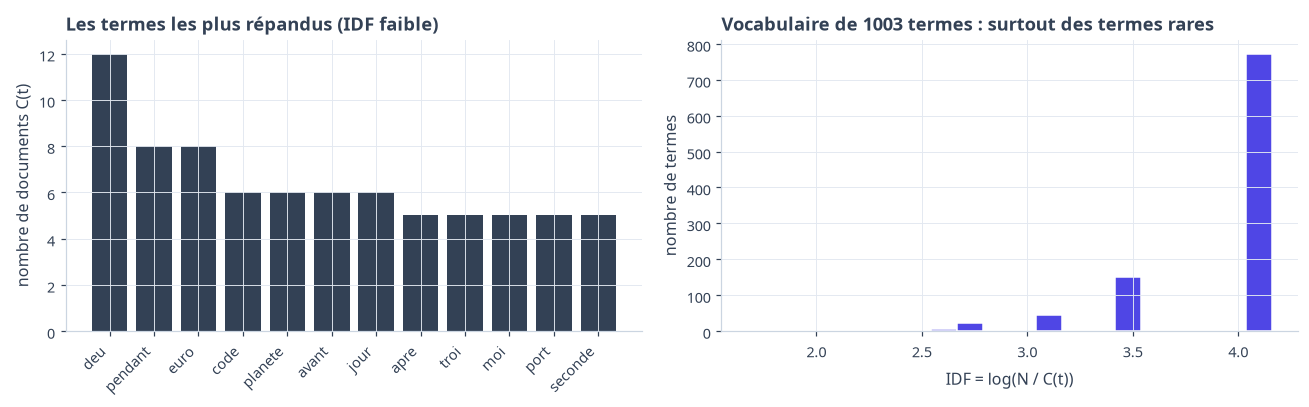

In [6]:
idf_all = np.array(sorted([np.log(len(P) / len(v)) for v in index.values()]))
dfreq = pd.Series({t: len(v) for t, v in index.items()}).sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axes[0]
top = dfreq.head(12)
ax.bar(top.index, top.values, color=SLATE)
ax.set_xticks(range(len(top))); ax.set_xticklabels(top.index, rotation=45, ha="right")
ax.set_ylabel("nombre de documents C(t)"); ax.set_title("Les termes les plus répandus (IDF faible)")
ax = axes[1]
ax.hist(idf_all, bins=20, color=INDIGO, edgecolor="white")
ax.set_xlabel("IDF = log(N / C(t))"); ax.set_ylabel("nombre de termes")
ax.set_title(f"Vocabulaire de {len(index)} termes : surtout des termes rares")
finish(fig); plt.show()

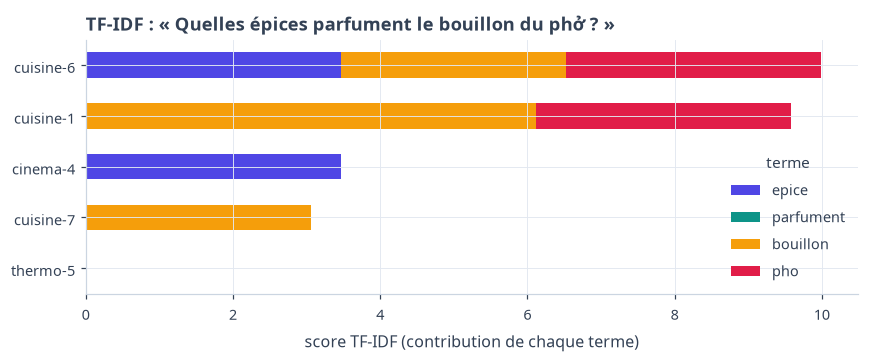

In [7]:
tfidf = c6.TfIdf(toks)
qtxt = "Quelles épices parfument le bouillon du phở ?"
s = tfidf.scores(c6.tokenize(qtxt))
top5 = np.argsort(-s)[:5]
contrib = pd.DataFrame({t: [tfidf.idf.get(t, 0) * toks[i].count(t) for i in top5] for t in c6.tokenize(qtxt)},
                       index=[IDS[i] for i in top5])
ax = contrib.plot.barh(stacked=True, figsize=(8, 3.4), color=[INDIGO, TEAL, AMBER, ROSE, VIOLET][:contrib.shape[1]])
ax.invert_yaxis(); ax.set_xlabel("score TF-IDF (contribution de chaque terme)")
ax.set_title("TF-IDF : « Quelles épices parfument le bouillon du phở ? »")
ax.legend(title="terme", loc="lower right"); plt.tight_layout(); plt.show()

Le passage attendu (`cuisine-1`, qui cite l'anis étoilé et la cannelle) n'utilise jamais le mot
« épice » : il ne marque des points qu'avec « bouillon » (deux fois) et « phở ». Le passage
`cuisine-6` (version végétarienne) contient le mot « épices » en plus de « bouillon » et «
phở » : il passe **devant**, alors qu'il ne répond pas à la question. La recherche lexicale ne
« comprend » pas, elle compte des mots.

> **À retenir.** TF-IDF = (combien de fois le terme apparaît) × (à quel point il est rare).
> L'**index inversé** rend la recherche très rapide ; la **tokenisation** (accents, codes,
> mots vides) conditionne fortement la qualité.

## 4. BM25 (section *Term-based retrieval*)

Le TF-IDF naïf a deux défauts : un terme répété 50 fois compte 50 fois plus qu'une fois, et un
long document accumule mécaniquement plus d'occurrences. **Okapi BM25** (Robertson et al.,
années 1980) corrige les deux :
$$\mathrm{BM25}(D, Q) = \sum_{t\in Q} \mathrm{IDF}(t)\,
  \frac{f(t,D)\,(k_1+1)}{f(t,D) + k_1\left(1 - b + b\,\frac{|D|}{\mathrm{avgdl}}\right)},
\qquad \mathrm{IDF}(t) = \log\frac{N - n_t + 0{,}5}{n_t + 0{,}5}.$$

- $k_1$ (souvent 1,2 à 2) règle la **saturation** : quand $f \to \infty$, la fraction tend vers
  $k_1 + 1$, le gain de chaque nouvelle occurrence diminue ;
- $b \in [0, 1]$ règle la **normalisation par la longueur** ($|D|$ : longueur du document,
  avgdl : longueur moyenne) ; $b = 0$ ignore la longueur.

Implémentons-le (classe `c6.BM25`) et vérifions qu'on retrouve exactement `rank_bm25`, qui
remplace les IDF négatives (termes présents dans plus de la moitié des documents) par une
petite fraction $\varepsilon$ de l'IDF moyenne.

Écart maximal BM25 maison / rank_bm25 sur les 42 questions : 3.55e-15


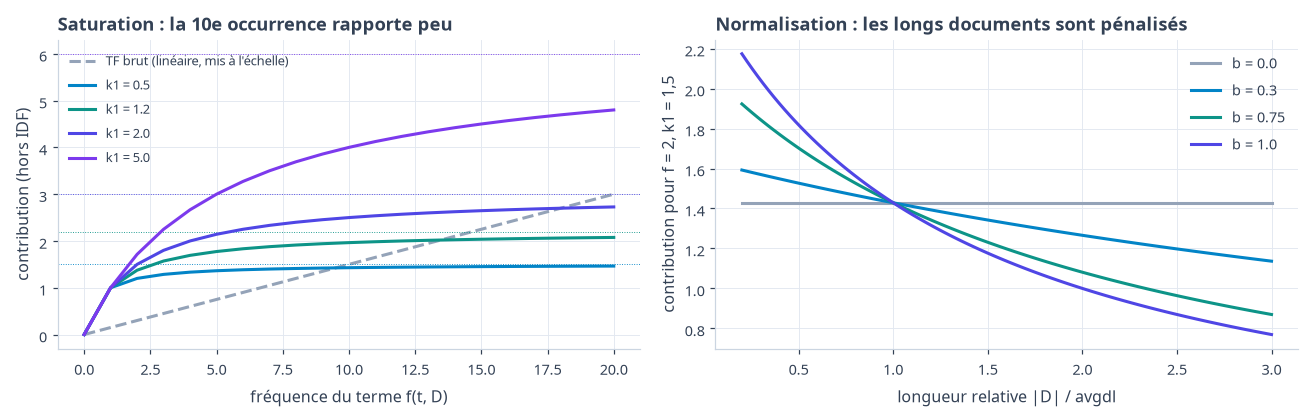

In [8]:
ecarts = []
for qd in c6.QUESTIONS:
    qt = c6.tokenize(qd["question"])
    ecarts.append(np.abs(c6.BM25(toks).scores(qt) - BM25Okapi(toks).get_scores(qt)).max())
print(f"Écart maximal BM25 maison / rank_bm25 sur les 42 questions : {max(ecarts):.2e}")

f = np.arange(0, 21)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
ax = axes[0]
ax.plot(f, f / f.max() * 3, color=GRAY, ls="--", label="TF brut (linéaire, mis à l'échelle)")
for k1, col in [(0.5, SKY), (1.2, TEAL), (2.0, INDIGO), (5.0, VIOLET)]:
    ax.plot(f, f * (k1 + 1) / (f + k1), color=col, label=f"k1 = {k1}")
    ax.axhline(k1 + 1, color=col, lw=0.6, ls=":")
ax.set_xlabel("fréquence du terme f(t, D)"); ax.set_ylabel("contribution (hors IDF)")
ax.set_title("Saturation : la 10e occurrence rapporte peu"); ax.legend(fontsize=8.5)
ax = axes[1]
ratio = np.linspace(0.2, 3, 100)
for b, col in [(0.0, GRAY), (0.3, SKY), (0.75, TEAL), (1.0, INDIGO)]:
    ax.plot(ratio, 2 * 2.5 / (2 + 1.5 * (1 - b + b * ratio)), color=col, label=f"b = {b}")
ax.set_xlabel("longueur relative |D| / avgdl"); ax.set_ylabel("contribution pour f = 2, k1 = 1,5")
ax.set_title("Normalisation : les longs documents sont pénalisés"); ax.legend()
finish(fig); plt.show()

Sur notre corpus, quelle est l'influence de $k_1$ et $b$ sur la qualité ? On mesure le
**MRR** (rang réciproque moyen du premier passage pertinent, défini au cours 2) sur les 42
questions. Une grille suffit, car BM25 se calcule en quelques millisecondes.

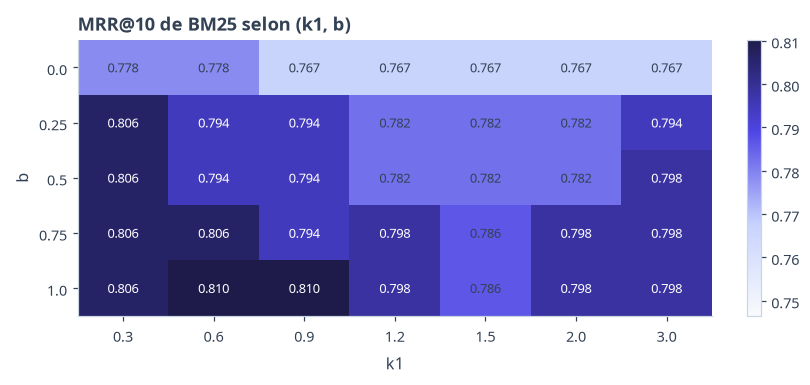

TF-IDF naïf : MRR@10 = 0.767


In [9]:
def mrr_bm25(k1, b):
    m = c6.BM25(toks, k1=k1, b=b)
    run = {qd["qid"]: c6.rank(m.scores(c6.tokenize(qd["question"])), IDS, 10) for qd in c6.QUESTIONS}
    return c6.evaluate(run, k=10)["MRR"]

k1s, bs = [0.3, 0.6, 0.9, 1.2, 1.5, 2.0, 3.0], [0.0, 0.25, 0.5, 0.75, 1.0]
grid = np.array([[mrr_bm25(k1, b) for k1 in k1s] for b in bs])
fig, ax = plt.subplots(figsize=(7.5, 3.6))
im = ax.imshow(grid, cmap="aie_seq", aspect="auto", vmin=grid.min() - 0.02, vmax=grid.max())
ax.set_xticks(range(len(k1s))); ax.set_xticklabels(k1s); ax.set_yticks(range(len(bs))); ax.set_yticklabels(bs)
for i in range(len(bs)):
    for j in range(len(k1s)):
        ax.text(j, i, f"{grid[i, j]:.3f}", ha="center", va="center", fontsize=8.5,
                color="white" if grid[i, j] > (grid.min() + grid.max()) / 2 else SLATE)
ax.set_xlabel("k1"); ax.set_ylabel("b"); ax.grid(False)
ax.set_title("MRR@10 de BM25 selon (k1, b)")
plt.colorbar(im, ax=ax, fraction=0.04); plt.tight_layout(); plt.show()
print(f"TF-IDF naïf : MRR@10 = {c6.evaluate({qd['qid']: c6.rank(tfidf.scores(c6.tokenize(qd['question'])), IDS, 10) for qd in c6.QUESTIONS}, k=10)['MRR']:.3f}")

Les écarts restent modestes : nos passages ont des longueurs proches, donc $b$ compte peu, et
les requêtes répètent rarement un terme. Sur un vrai corpus (pages de longueurs très
variables), la normalisation pèse davantage. La robustesse de BM25 aux réglages explique qu'il
reste une **référence redoutable** : le livre rapporte le mot du PDG de Perplexity, pour qui
faire vraiment mieux que BM25 est difficile.

> **À retenir.** BM25 = TF-IDF avec **saturation** ($k_1$) et **normalisation par la
> longueur** ($b$). Rapide, sans entraînement, peu sensible à ses hyperparamètres : c'est la
> ligne de base à battre.

## 5. Recherche par embeddings (section *Embedding-based retrieval*)

La recherche lexicale travaille sur la **forme** des mots, pas sur leur **sens** : «
transformer architecture » peut ramener des transformateurs électriques, et « vacances » ne
trouve pas « congés payés ». La recherche **sémantique** encode requête et documents en
vecteurs (embeddings, chapitre 3) et classe les documents par similarité cosinus :
$$\cos(\mathbf q, \mathbf d) = \frac{\mathbf q \cdot \mathbf d}{\|\mathbf q\|\,\|\mathbf d\|}.$$
Avec des vecteurs normalisés, c'est un simple produit scalaire. L'indexation gagne une étape
(calculer les embeddings des morceaux, stockés dans une **base vectorielle**) et la requête
aussi (encoder la question avec **le même** modèle).

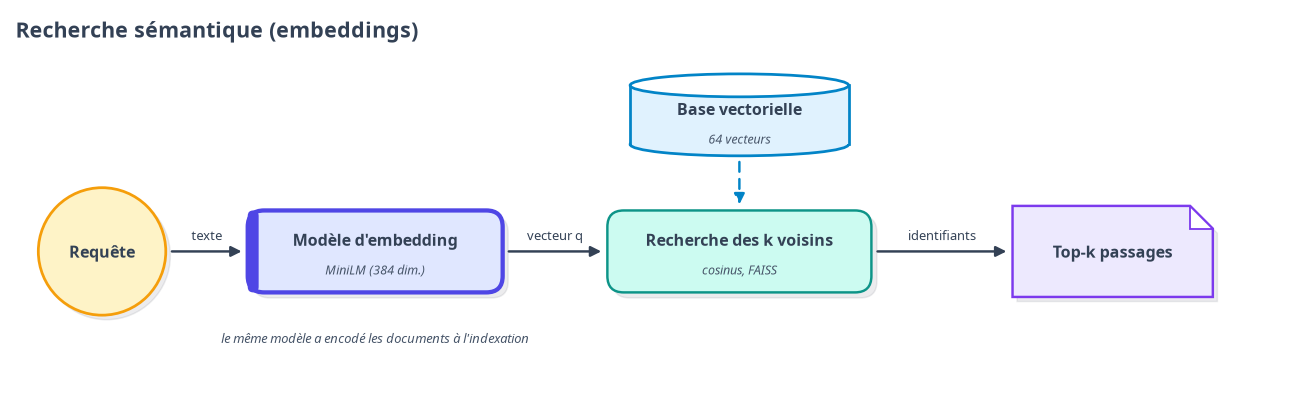

In [10]:
d = Diagram(14, 3.6, title="Recherche sémantique (embeddings)")
d.box("q", 1.0, 1.5, "Requête", color=AMBER, kind="user", w=1.4)
d.box("emb", 4.0, 1.5, "Modèle d'embedding", sub="MiniLM (384 dim.)", color=INDIGO, kind="model", w=2.8)
d.box("knn", 8.0, 1.5, "Recherche des k voisins", sub="cosinus, FAISS", color=TEAL, w=2.9)
d.box("db", 8.0, 3.0, "Base vectorielle", sub="64 vecteurs", color=SKY, kind="db", w=2.4, h=0.9)
d.box("top", 12.1, 1.5, "Top-k passages", color=VIOLET, kind="doc", w=2.2, h=1.0)
d.arrow("q", "emb", "texte"); d.arrow("emb", "knn", "vecteur q"); d.arrow("db", "knn", style="dashed", color=SKY)
d.arrow("knn", "top", "identifiants")
d.note(4.0, 0.55, "le même modèle a encodé les documents à l'indexation", fontsize=8.5)
d.show()

Comparons deux modèles déjà téléchargés : `all-MiniLM-L6-v2` (entraîné surtout sur de
l'anglais) et `paraphrase-multilingual-MiniLM-L12-v2` (multilingue, dont le français). Une
projection en 2D (ACP) des embeddings des passages montre si les documents forment des
groupes thématiques.

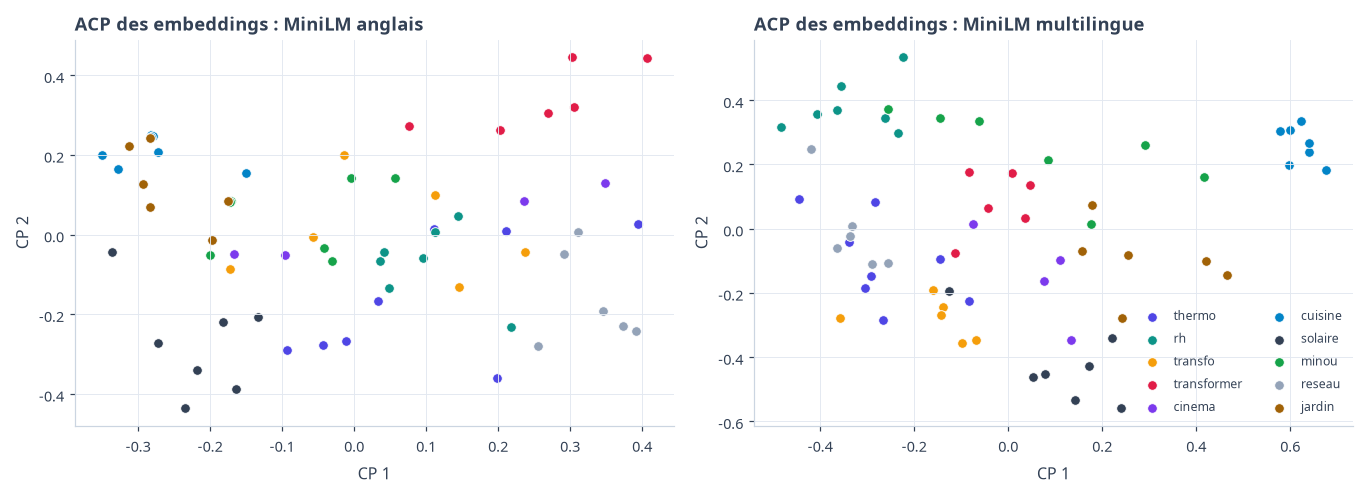

In [11]:
dense_en = c6.DenseRetriever(TEXTS, IDS, llm.EMBED)
dense_ml = c6.DenseRetriever(TEXTS, IDS, llm.EMBED_MULTI)
docs_of = [p.doc for p in P]
doc_names = [d_["doc"] for d_ in c6.DOCUMENTS]
pal = dict(zip(doc_names, COLORS + [GRAY, "#A16207"]))
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
for ax, (nom, r) in zip(axes, [("MiniLM anglais", dense_en), ("MiniLM multilingue", dense_ml)]):
    Z = PCA(2, random_state=0).fit_transform(r.emb)
    for dn in doc_names:
        m = np.array([x == dn for x in docs_of])
        ax.scatter(Z[m, 0], Z[m, 1], s=40, color=pal[dn], label=dn, edgecolor="white", lw=0.6)
    ax.set_title(f"ACP des embeddings : {nom}"); ax.set_xlabel("CP 1"); ax.set_ylabel("CP 2")
axes[1].legend(fontsize=8, ncol=2, loc="best")
finish(fig); plt.show()

Les groupes thématiques sont nettement plus séparés avec le modèle multilingue. Regardons la
matrice de similarité questions × passages : idéalement, la case la plus claire de chaque
ligne tombe sur le passage pertinent (losanges).

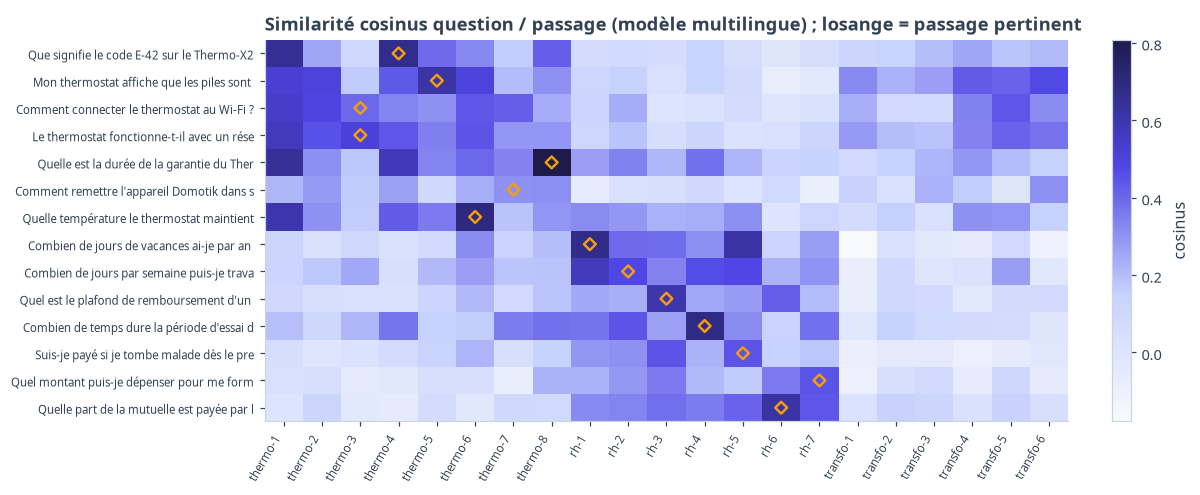

In [12]:
qs = c6.QUESTIONS[:14]
Eq = llm.embed([qd["question"] for qd in qs], llm.EMBED_MULTI)
idx_p = list(range(0, 21))
S = Eq @ dense_ml.emb[idx_p].T
fig, ax = plt.subplots(figsize=(11, 4.6))
im = ax.imshow(S, cmap="aie_seq", aspect="auto")
for i, qd in enumerate(qs):
    for r_ in qd["relevant"]:
        j = IDS.index(r_)
        if j in idx_p:
            ax.scatter(j, i, marker="D", s=30, facecolor="none", edgecolor=AMBER, lw=1.6)
ax.set_yticks(range(len(qs))); ax.set_yticklabels([qd["question"][:42] for qd in qs], fontsize=7.5)
ax.set_xticks(range(len(idx_p))); ax.set_xticklabels([IDS[j] for j in idx_p], rotation=60, ha="right", fontsize=7.5)
ax.grid(False); plt.colorbar(im, ax=ax, fraction=0.03, label="cosinus")
ax.set_title("Similarité cosinus question / passage (modèle multilingue) ; losange = passage pertinent")
plt.tight_layout(); plt.show()

Comparons maintenant BM25 et la recherche dense sur quelques questions typiques : laquelle
place le bon passage en tête ?

In [13]:
bm25 = c6.TermRetriever(TEXTS, IDS)
cas = ["q07", "q29", "q33", "q36", "q04", "q06"]
rows = []
for qid in cas:
    qd = next(x for x in c6.QUESTIONS if x["qid"] == qid)
    row = {"question": qd["question"][:60], "type": qd["type"], "pertinent": ", ".join(qd["relevant"])}
    for nom, r in [("BM25", bm25), ("dense EN", dense_en), ("dense multi", dense_ml)]:
        top1 = r.search(qd["question"], 1)[0]
        row[nom] = top1 + (" ✓" if top1 in qd["relevant"] else " ✗")
    rows.append(row)
pd.DataFrame(rows)

,question,type,pertinent,BM25,dense EN,dense multi
0,Quelle température le thermostat maintient-il quand je pars,semantique,thermo-6,thermo-1 ✗,thermo-1 ✗,thermo-6 ✓
1,Combien de temps la lumière solaire met-elle à nous parvenir,semantique,solaire-7,rh-7 ✗,solaire-1 ✗,solaire-7 ✓
2,À partir de quel montant la livraison est-elle gratuite chez,semantique,minou-5,minou-1 ✗,minou-1 ✗,minou-5 ✓
3,Que signifie l'erreur EADDRNOTAVAIL ?,lexical,reseau-2,reseau-2 ✓,rh-5 ✗,reseau-4 ✗
4,Le thermostat fonctionne-t-il avec un réseau 5 GHz ?,lexical,thermo-3,thermo-3 ✓,thermo-3 ✓,thermo-1 ✗
5,Comment remettre l'appareil Domotik dans son état d'origine,semantique,thermo-7,reseau-5 ✗,minou-6 ✗,minou-6 ✗


Les paraphrases (« je pars en congé » pour le mode vacances, « lumière solaire » pour «
lumière du Soleil », « gratuite » pour « offerte ») profitent au modèle multilingue, alors que
les identifiants rares (EADDRNOTAVAIL, « 5 GHz ») sont le terrain de BM25 : un embedding peut «
diluer » un code d'erreur, comme le souligne le livre. La dernière question (« état d'origine »
pour « réglages d'usine ») piège tout le monde. Le modèle anglais, lui, comprend mal le
français. Le choix du modèle d'embedding compte autant que l'algorithme : un
retriever sémantique n'est jamais meilleur que ses embeddings.

> **À retenir.** La recherche dense compare des **sens** (cosinus entre embeddings) et gère
> les paraphrases ; elle exige un modèle d'embedding adapté à la langue et au domaine, et peut
> rater les mots-clés exacts (codes, noms de produits).

## 6. Recherche vectorielle exacte et approchée (section *Embedding-based retrieval*)

Trouver les $k$ vecteurs les plus proches d'une requête parmi $N$ vecteurs de dimension $d$
par force brute (k-NN exact) coûte $N \cdot d$ multiplications-additions **par requête**.
Ordres de grandeur, pour $d = 768$ en float32 :

| $N$ | mémoire ($4Nd$ octets) | opérations / requête |
|---|---|---|
| $10^4$ | 31 Mo | $7{,}7 \cdot 10^6$ |
| $10^6$ | 3,1 Go | $7{,}7 \cdot 10^8$ |
| $10^8$ | 307 Go | $7{,}7 \cdot 10^{10}$ |

Au-delà du million de vecteurs, on passe à la recherche **approchée** (ANN) : on accepte de
rater quelques vrais voisins pour aller beaucoup plus vite. Les bases vectorielles organisent
les vecteurs en **seaux**, **arbres** ou **graphes**, et peuvent les **quantifier**. Illustrons
deux idées majeures en 2D.

**IVF (*inverted file index*).** Un k-means partitionne l'espace en cellules ; à la requête, on
ne visite que les `nprobe` cellules dont le centroïde est le plus proche.

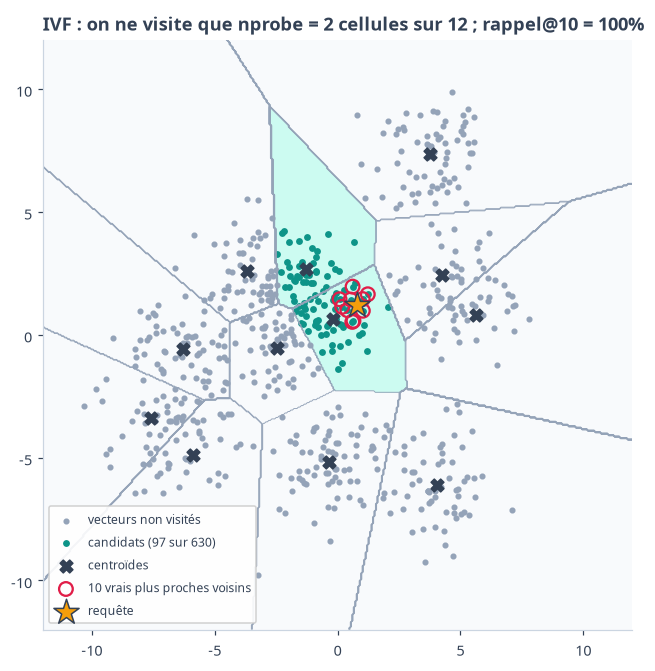

In [14]:
rng = np.random.default_rng(3)
centres = rng.uniform(-8, 8, size=(9, 2))
X2 = np.vstack([c_ + rng.normal(scale=1.3, size=(70, 2)) for c_ in centres])
km = KMeans(12, n_init=4, random_state=0).fit(X2)
qpt = np.array([0.8, 1.2])
dist_c = ((km.cluster_centers_ - qpt) ** 2).sum(1)
probe = np.argsort(dist_c)[:2]
cand = np.isin(km.labels_, probe)
true10 = np.argsort(((X2 - qpt) ** 2).sum(1))[:10]
found = [i for i in np.argsort(((X2 - qpt) ** 2).sum(1)) if cand[i]][:10]
gx, gy = np.meshgrid(np.linspace(-12, 12, 400), np.linspace(-12, 12, 400))
lab = km.predict(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)

fig, ax = plt.subplots(figsize=(7.6, 6.2))
shade = np.isin(lab, probe).astype(float)
ax.contourf(gx, gy, shade, levels=[-0.5, 0.5, 1.5], colors=["#F8FAFC", LIGHT[TEAL]])
ax.contour(gx, gy, lab, levels=np.arange(13) - 0.5, colors=GRAY, linewidths=0.6)
ax.scatter(X2[~cand, 0], X2[~cand, 1], s=9, color=GRAY, label="vecteurs non visités")
ax.scatter(X2[cand, 0], X2[cand, 1], s=12, color=TEAL, label=f"candidats ({cand.sum()} sur {len(X2)})")
ax.scatter(*km.cluster_centers_.T, marker="X", s=70, color=SLATE, label="centroïdes")
ax.scatter(X2[true10, 0], X2[true10, 1], s=80, facecolor="none", edgecolor=ROSE, lw=1.5, label="10 vrais plus proches voisins")
ax.scatter(*qpt, marker="*", s=300, color=AMBER, edgecolor=SLATE, zorder=5, label="requête")
ax.set_xlim(-12, 12); ax.set_ylim(-12, 12); ax.set_aspect("equal"); ax.grid(False)
rec = len(set(found) & set(true10)) / 10
ax.set_title(f"IVF : on ne visite que nprobe = 2 cellules sur 12 ; rappel@10 = {rec:.0%}")
ax.legend(fontsize=8, loc="lower left", framealpha=0.9, frameon=True)
plt.tight_layout(); plt.show()

On calcule les distances pour une fraction seulement des points ; les voisins situés juste de
l'autre côté d'une frontière de cellule sont manqués si leur cellule n'est pas visitée : d'où
un compromis rappel / vitesse réglé par `nprobe`. Le livre indique qu'on vise en pratique 100
à 10 000 vecteurs par cellule.

**Graphes de voisinage (NSW, HNSW).** Chaque vecteur est relié à ses voisins proches ; une
recherche **gloutonne** part d'un point d'entrée et saute de voisin en voisin vers la requête.
HNSW ajoute une **hiérarchie** : une couche supérieure clairsemée (longs sauts, comme une
autoroute) puis des couches de plus en plus denses (routes locales).

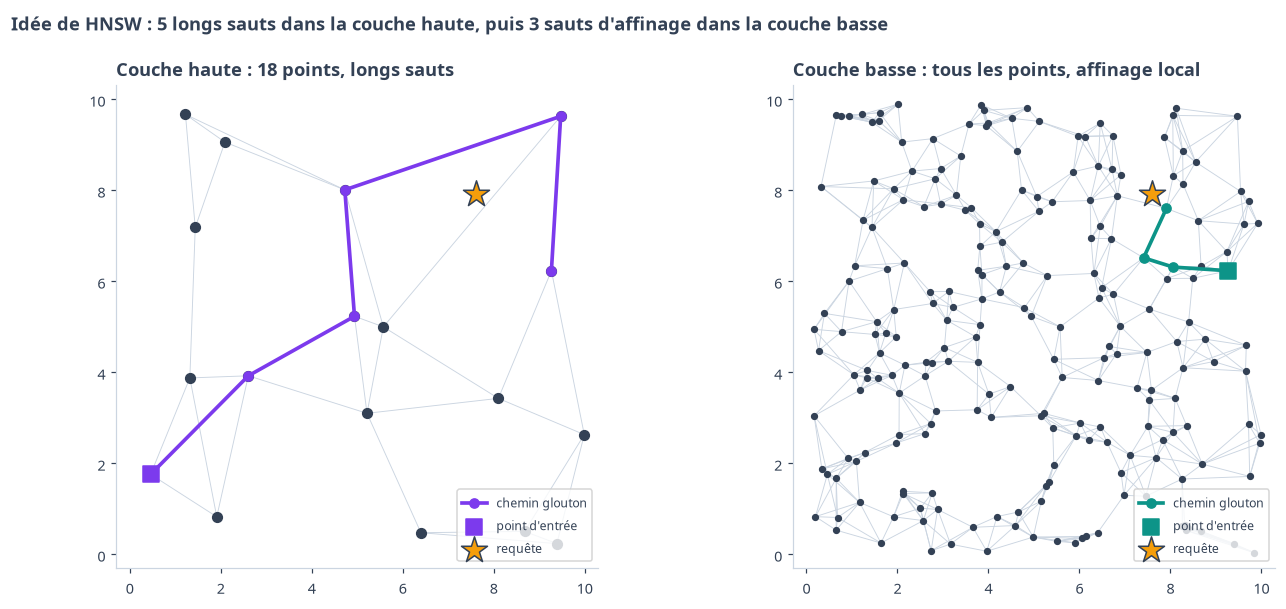

Point trouvé : 67, vrai plus proche voisin : 67


In [15]:
rng = np.random.default_rng(1)
Xg = rng.uniform(0, 10, size=(220, 2))
qg = np.array([7.6, 7.9])
haut = rng.choice(len(Xg), 18, replace=False)
G_haut = c6.knn_graph(Xg[haut], m=3)
G_bas = c6.knn_graph(Xg, m=5)
entry_local = int(np.argmin(((Xg[haut] - np.array([0.5, 0.5])) ** 2).sum(1)))
path_h_loc = c6.greedy_graph_search(Xg[haut], G_haut, qg, entry_local)
path_h = [haut[i] for i in path_h_loc]
path_b = c6.greedy_graph_search(Xg, G_bas, qg, path_h[-1])
path_plat = c6.greedy_graph_search(Xg, G_bas, qg, haut[entry_local])
cout = lambda path, G: sum(len(G[i]) for i in path)  # noqa: E731  distances calculées

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.6))
for ax, (titre, pts, G, path, col) in zip(axes, [
        ("Couche haute : 18 points, longs sauts", Xg[haut], G_haut, path_h_loc, VIOLET),
        ("Couche basse : tous les points, affinage local", Xg, G_bas, path_b, TEAL)]):
    for i, nb in enumerate(G):
        for j in nb:
            if j > i:
                ax.plot(*pts[[i, j]].T, color="#CBD5E1", lw=0.6, zorder=1)
    ax.scatter(*pts.T, s=14 if len(pts) > 50 else 40, color=SLATE, zorder=2)
    ax.plot(*pts[path].T, color=col, lw=2.4, marker="o", ms=6, zorder=3, label="chemin glouton")
    ax.scatter(*pts[path[0]], s=120, color=col, marker="s", zorder=4, label="point d'entrée")
    ax.scatter(*qg, marker="*", s=320, color=AMBER, edgecolor=SLATE, zorder=5, label="requête")
    ax.set_xlim(-0.3, 10.3); ax.set_ylim(-0.3, 10.3); ax.set_aspect("equal"); ax.grid(False)
    ax.set_title(titre); ax.legend(fontsize=8, loc="lower right", frameon=True)
fig.suptitle(f"Idée de HNSW : {len(path_h_loc) - 1} longs sauts dans la couche haute, "
             f"puis {len(path_b) - 1} sauts d'affinage dans la couche basse", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()
d_true = np.argmin(((Xg - qg) ** 2).sum(1))
print(f"Point trouvé : {path_b[-1]}, vrai plus proche voisin : {d_true}")

Sur 220 points, l'avantage est invisible. Mesurons-le sur 3 000 points et 300 requêtes
aléatoires : graphe à un seul niveau (point d'entrée fixe) contre hiérarchie à trois niveaux
(12, 150 puis 3 000 points). On compte les distances calculées et le taux de succès (le point
renvoyé est-il le vrai plus proche voisin ?).

In [16]:
rng = np.random.default_rng(0)
X3 = rng.uniform(0, 10, (3000, 2))
G0 = c6.knn_graph(X3, 6)
n1 = rng.choice(3000, 150, replace=False); G1 = c6.knn_graph(X3[n1], 4)
n2 = rng.choice(150, 12, replace=False); G2 = c6.knn_graph(X3[n1][n2], 3)
stats = {"graphe à un niveau": [], "hiérarchie à 3 niveaux": []}
for _ in range(300):
    q3 = rng.uniform(0, 10, 2)
    vrai = np.argmin(((X3 - q3) ** 2).sum(1))
    p = c6.greedy_graph_search(X3, G0, q3, n1[n2[0]])
    stats["graphe à un niveau"].append((cout(p, G0), p[-1] == vrai))
    p2 = c6.greedy_graph_search(X3[n1][n2], G2, q3, 0)
    p1 = c6.greedy_graph_search(X3[n1], G1, q3, n2[p2[-1]])
    p0 = c6.greedy_graph_search(X3, G0, q3, n1[p1[-1]])
    stats["hiérarchie à 3 niveaux"].append((cout(p2, G2) + cout(p1, G1) + cout(p0, G0), p0[-1] == vrai))
tab_g = pd.DataFrame({k_: {"distances calculées (moyenne)": np.mean([a for a, _ in v]),
                           "succès (vrai plus proche voisin)": np.mean([b for _, b in v])} for k_, v in stats.items()}).T
tab_g.loc["force brute"] = [3000, 1.0]
tab_g.round(2)

,distances calculées (moyenne),succès (vrai plus proche voisin)
graphe à un niveau,117.32,0.55
hiérarchie à 3 niveaux,48.23,0.88
force brute,3000.00,1.00


La hiérarchie divise le nombre de distances calculées et, surtout, évite que la descente
gloutonne reste bloquée dans un minimum local loin de la cible. Le vrai HNSW va plus loin : il
garde une liste de candidats (paramètre `efSearch`) au lieu d'un seul point courant, ce qui
fait monter le succès près de 100 %.

Mesurons maintenant ces compromis à une échelle plus réaliste avec **FAISS** : 100 000
vecteurs synthétiques de dimension 64 (regroupés en 200 amas, comme des embeddings
thématiques), 300 requêtes, sur **un seul cœur** pour mesurer une latence honnête. On compare
la force brute (`IndexFlat`), IVF (256 cellules, `nprobe` variable), IVF avec quantification
par produit (PQ : chaque vecteur est découpé en 16 sous-vecteurs codés sur un octet chacun) et
HNSW (`efSearch` variable).

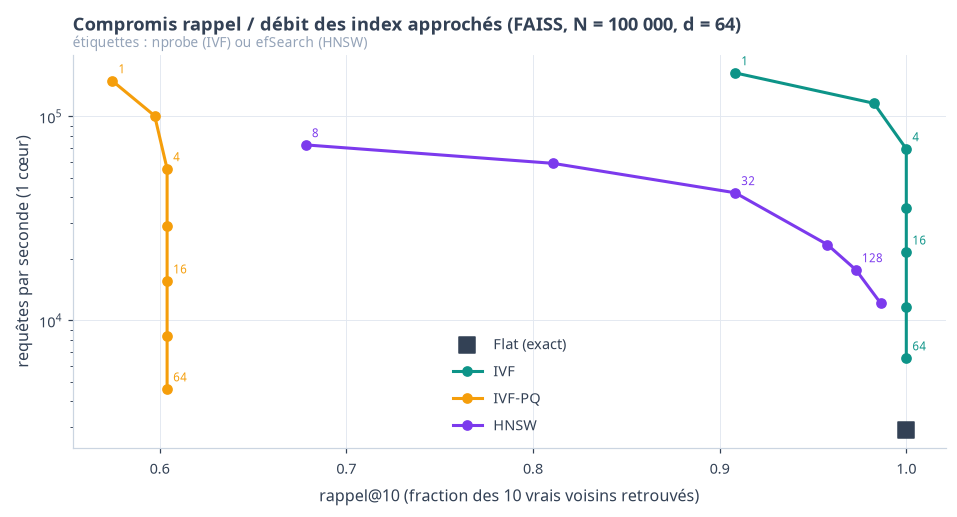

,construction (s),taille de l'index (Mo)
Flat,0.00,25.60
IVF,0.07,26.47
IVF-PQ,1.09,2.53
HNSW,0.28,40.03


In [17]:
faiss.omp_set_num_threads(1)
rng = np.random.default_rng(0)
dim, N, nq = 64, 100_000, 300
C = rng.normal(size=(200, dim)).astype("float32") * 2
Xb = (C[rng.integers(0, 200, N)] + rng.normal(size=(N, dim))).astype("float32")
Xq = (C[rng.integers(0, 200, nq)] + rng.normal(size=(nq, dim))).astype("float32")
flat = faiss.IndexFlatL2(dim); flat.add(Xb)
t = time.perf_counter(); _, gt = flat.search(Xq, 10); t_flat = time.perf_counter() - t

def bench(index, param_name, values):
    out = []
    for v in values:
        faiss.ParameterSpace().set_index_parameter(index, param_name, v)
        t = time.perf_counter(); _, I = index.search(Xq, 10); dt = time.perf_counter() - t
        rec = np.mean([len(set(I[i]) & set(gt[i])) / 10 for i in range(nq)])
        out.append((v, rec, nq / dt))
    return out

faiss.omp_set_num_threads(8)  # construction parallèle
res, build, taille = {}, {}, {}
t = time.perf_counter(); ivf = faiss.IndexIVFFlat(faiss.IndexFlatL2(dim), dim, 256); ivf.train(Xb[:30000]); ivf.add(Xb); build["IVF"] = time.perf_counter() - t
t = time.perf_counter(); ivfpq = faiss.IndexIVFPQ(faiss.IndexFlatL2(dim), dim, 256, 16, 8); ivfpq.train(Xb[:30000]); ivfpq.add(Xb); build["IVF-PQ"] = time.perf_counter() - t
t = time.perf_counter(); hnsw = faiss.IndexHNSWFlat(dim, 16); hnsw.hnsw.efConstruction = 40; hnsw.add(Xb); build["HNSW"] = time.perf_counter() - t
faiss.omp_set_num_threads(1)
res["IVF"] = bench(ivf, "nprobe", [1, 2, 4, 8, 16, 32, 64])
res["IVF-PQ"] = bench(ivfpq, "nprobe", [1, 2, 4, 8, 16, 32, 64])
res["HNSW"] = bench(hnsw, "efSearch", [8, 16, 32, 64, 128, 256])
for nom, idx in [("Flat", flat), ("IVF", ivf), ("IVF-PQ", ivfpq), ("HNSW", hnsw)]:
    taille[nom] = len(faiss.serialize_index(idx)) / 1e6

fig, ax = plt.subplots(figsize=(8.8, 4.8))
ax.scatter([1.0], [nq / t_flat], s=120, marker="s", color=SLATE, zorder=3, label="Flat (exact)")
for (nom, pts), col in zip(res.items(), [TEAL, AMBER, VIOLET]):
    r_, q_ = [p[1] for p in pts], [p[2] for p in pts]
    ax.plot(r_, q_, marker="o", color=col, label=nom)
    for v, rr, qq in pts[::2]:
        ax.annotate(str(v), (rr, qq), textcoords="offset points", xytext=(4, 5), fontsize=7.5, color=col)
ax.set_yscale("log"); ax.set_xlabel("rappel@10 (fraction des 10 vrais voisins retrouvés)")
ax.set_ylabel("requêtes par seconde (1 cœur)")
ax.set_title("Compromis rappel / débit des index approchés (FAISS, N = 100 000, d = 64)", pad=16)
subtitle(ax, "étiquettes : nprobe (IVF) ou efSearch (HNSW)")
ax.legend(); plt.tight_layout(); plt.show()
pd.DataFrame({"construction (s)": {"Flat": 0.0, **build}, "taille de l'index (Mo)": taille}).round(2)

On retrouve les quatre critères de l'ANN-Benchmarks cités par le livre : **rappel**, **débit**
(QPS), **temps de construction** et **taille de l'index**. Les deux index approchés sont 10 à
30 fois plus rapides que la force brute pour un rappel de 90 à 100 %. Nos données sont très
regroupées en amas, ce qui avantage IVF (ses cellules épousent les amas) ; HNSW demande un
`efSearch` plus grand pour approcher un rappel de 1, et son index est plus gros que les
données (il stocke le graphe). IVF-PQ divise la mémoire par 10 (16 octets par vecteur au lieu
de 256) mais plafonne en rappel, car les distances sont calculées sur des vecteurs compressés
(en pratique, on reclasse les candidats avec les vecteurs exacts). La force brute reste
imbattable en rappel et très correcte à 100 000 vecteurs : pour nos 64 passages, un simple
produit matriciel suffit.

> **À retenir.** k-NN exact : $O(Nd)$ par requête. Les index ANN échangent un peu de rappel
> contre beaucoup de vitesse : **IVF** (visiter quelques cellules d'un k-means), **HNSW**
> (descendre un graphe hiérarchique), **PQ** (compresser les vecteurs). On les compare sur
> rappel, débit, temps de construction et mémoire.

## 7. Comparer recherche par termes et par embeddings (section *Comparing retrieval algorithms*)

Le livre résume la comparaison (tableau 6-2) : la recherche par termes est **plus rapide et
moins chère**, performante d'emblée mais difficile à améliorer ; la recherche par embeddings
est plus coûteuse (encodage, stockage, recherche vectorielle) mais gère des requêtes plus
naturelles et peut être améliorée par affinage. Mesurons la vitesse puis la qualité par type de
question.

                         indexation (ms)  requête (ms)
BM25 (Python pur)                   4.17          0.04
dense multilingue (GPU)            97.89          9.08


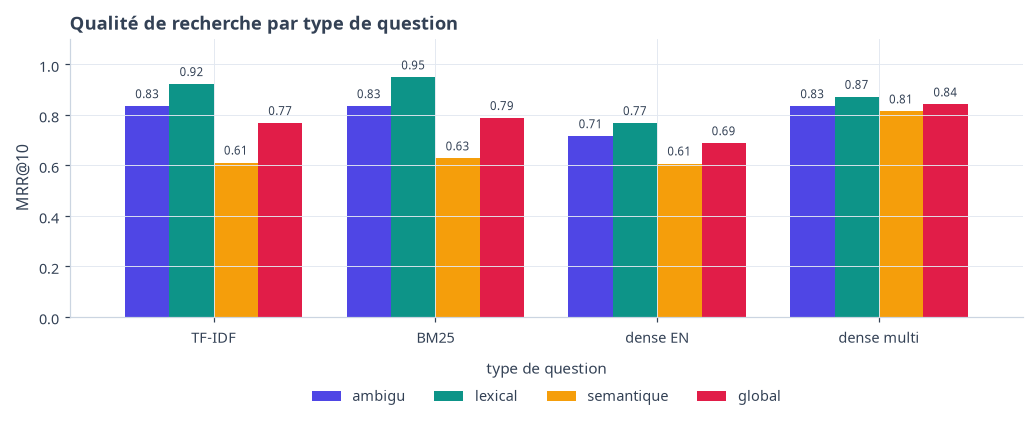

In [18]:
def chrono(fn, n=30):
    fn()
    t = time.perf_counter()
    for _ in range(n):
        fn()
    return (time.perf_counter() - t) / n * 1000

qtest = c6.QUESTIONS[0]["question"]
mesures = pd.DataFrame({
    "indexation (ms)": [chrono(lambda: c6.TermRetriever(TEXTS, IDS), 5), chrono(lambda: llm.embed(TEXTS, llm.EMBED_MULTI), 5)],
    "requête (ms)": [chrono(lambda: bm25.search(qtest, 5)), chrono(lambda: dense_ml.search(qtest, 5))],
}, index=["BM25 (Python pur)", "dense multilingue (GPU)"])
print(mesures.round(2))

runs = {"TF-IDF": c6.TermRetriever(TEXTS, IDS, "tfidf"), "BM25": bm25, "dense EN": dense_en, "dense multi": dense_ml}
runs = {n: {qd["qid"]: r.search(qd["question"], 10) for qd in c6.QUESTIONS} for n, r in runs.items()}
tab = pd.DataFrame({n: c6.per_question(r, k=10).groupby("type")["RR"].mean() for n, r in runs.items()})
tab.loc["global"] = [c6.evaluate(r, k=10)["MRR"] for r in runs.values()]
ax = tab.T.plot.bar(figsize=(9.5, 4), color=[INDIGO, TEAL, AMBER, ROSE], width=0.8, rot=0)
annotate_bars(ax, "{:.2f}", fontsize=7.5)
ax.set_ylabel("MRR@10"); ax.set_xlabel(""); ax.set_ylim(0, 1.1); ax.set_title("Qualité de recherche par type de question")
ax.legend(title="type de question", ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.tight_layout(); plt.show()

La requête BM25 en Python pur se compte en dixièmes de milliseconde, alors que la recherche
dense doit d'abord faire passer la question dans un réseau de neurones (quelques
millisecondes, même sur GPU) ; l'indexation dense est elle aussi bien plus coûteuse (à
refaire à chaque changement de données ou de modèle). Côté qualité, BM25 domine sur les
questions lexicales et le modèle multilingue sur les questions sémantiques : les deux familles
sont **complémentaires**, ce qui motive la **recherche hybride** du cours 2. Rappelons qu'en
production, la latence du RAG est le plus souvent dominée par la génération, et que le coût
des bases vectorielles peut représenter une part notable des dépenses (le livre évoque un
cinquième à la moitié du budget d'API de modèles chez certaines entreprises).

> **À retenir.** Termes : rapide, bon marché, excellent sur les mots-clés exacts. Embeddings :
> plus lent et plus cher, meilleur sur les paraphrases, améliorable par affinage. Les combiner
> donne souvent le meilleur des deux.

## Synthèse

- Le **RAG** construit, pour chaque requête, un contexte réduit aux informations pertinentes ;
  son coût en tokens ne dépend pas de la taille de la base, contrairement au « tout dans le
  contexte ».
- Architecture : **indexation** hors ligne (découpage, représentation, index) puis, en ligne,
  **recherche** (éventuellement réécriture et reranking) et **génération**.
- **Recherche par termes** : tokenisation, index inversé, TF-IDF, puis **BM25** (saturation
  $k_1$, normalisation $b$), implémenté à la main et identique à `rank_bm25`.
- **Recherche dense** : embeddings + cosinus ; le choix du modèle (ici multilingue) est
  décisif. À grande échelle, les index **ANN** (IVF, HNSW, PQ) échangent un peu de rappel
  contre beaucoup de vitesse.
- Les deux familles ont des forces complémentaires.

**Liens.** Embeddings et similarité : chapitre 3. Efficacité du contexte et position de
l'information : chapitre 5. Suite du chapitre : évaluer et optimiser la recherche (cours 2),
RAG de bout en bout (cours 3), agents et mémoire (cours 4).

In [19]:
c6.free_models()